# Crop Yield Prediction Using Machine Learning

## ML Capstone Project — Review 1

**Group Name:** DATA MINDS

### Objective
The objective of this project is to predict crop yield using agricultural and environmental factors such as rainfall, temperature, pesticide usage, crop information, and other available features.

### Problem Type
**Regression**

### Dataset
Crop Yield Prediction Dataset

### Review 1
This notebook implements and compares multiple regression algorithms and evaluates their performance using appropriate regression metrics.

In [6]:
# Import libraries for data handling
import numpy as np
import pandas as pd

# Import libraries for visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Import preprocessing tools
from sklearn.model_selection import train_test_split

# Display settings
pd.set_option("display.max_columns", None)

print("Libraries imported successfully ✅")

Libraries imported successfully ✅


In [7]:
import os

data_path = "../data/crop_yield"

print("Files available:")
for file in os.listdir(data_path):
    print(file)

Files available:
pesticides.csv
rainfall.csv
temp.csv
yield.csv
yield_df.csv


In [8]:
# Load all Crop Yield CSV files

pesticides_df = pd.read_csv("../data/crop_yield/pesticides.csv")
rainfall_df = pd.read_csv("../data/crop_yield/rainfall.csv")
temp_df = pd.read_csv("../data/crop_yield/temp.csv")
yield_df = pd.read_csv("../data/crop_yield/yield.csv")
yield_combined_df = pd.read_csv("../data/crop_yield/yield_df.csv")

print("DATASET SHAPES")
print("----------------")
print("Pesticides :", pesticides_df.shape)
print("Rainfall   :", rainfall_df.shape)
print("Temperature:", temp_df.shape)
print("Yield      :", yield_df.shape)
print("Yield DF   :", yield_combined_df.shape)

DATASET SHAPES
----------------
Pesticides : (4349, 7)
Rainfall   : (6727, 3)
Temperature: (71311, 3)
Yield      : (56717, 12)
Yield DF   : (28242, 8)


In [9]:
print("Pesticides columns:")
print(pesticides_df.columns.tolist())

print("\nRainfall columns:")
print(rainfall_df.columns.tolist())

print("\nTemperature columns:")
print(temp_df.columns.tolist())

print("\nYield columns:")
print(yield_df.columns.tolist())

print("\nCombined Yield DF columns:")
print(yield_combined_df.columns.tolist())

Pesticides columns:
['Domain', 'Area', 'Element', 'Item', 'Year', 'Unit', 'Value']

Rainfall columns:
[' Area', 'Year', 'average_rain_fall_mm_per_year']

Temperature columns:
['year', 'country', 'avg_temp']

Yield columns:
['Domain Code', 'Domain', 'Area Code', 'Area', 'Element Code', 'Element', 'Item Code', 'Item', 'Year Code', 'Year', 'Unit', 'Value']

Combined Yield DF columns:
['Unnamed: 0', 'Area', 'Item', 'Year', 'hg/ha_yield', 'average_rain_fall_mm_per_year', 'pesticides_tonnes', 'avg_temp']


In [11]:
print("First 5 rows of yield_df:")
display(yield_df.head())

print("\nFirst 5 rows of yield_combined_df:")
display(yield_combined_df.head())

First 5 rows of yield_df:


,Domain Code,Domain,Area Code,Area,Element Code,Element,Item Code,Item,Year Code,Year,Unit,Value
0,QC,Crops,2,Afghanistan,5419,Yield,56,Maize,1961,1961,hg/ha,14000
1,QC,Crops,2,Afghanistan,5419,Yield,56,Maize,1962,1962,hg/ha,14000
2,QC,Crops,2,Afghanistan,5419,Yield,56,Maize,1963,1963,hg/ha,14260
3,QC,Crops,2,Afghanistan,5419,Yield,56,Maize,1964,1964,hg/ha,14257
4,QC,Crops,2,Afghanistan,5419,Yield,56,Maize,1965,1965,hg/ha,14400



First 5 rows of yield_combined_df:


,Unnamed: 0,Area,Item,Year,hg/ha_yield,average_rain_fall_mm_per_year,pesticides_tonnes,avg_temp
0,0,Albania,Maize,1990,36613,1485.0,121.0,16.37
1,1,Albania,Potatoes,1990,66667,1485.0,121.0,16.37
2,2,Albania,"Rice, paddy",1990,23333,1485.0,121.0,16.37
3,3,Albania,Sorghum,1990,12500,1485.0,121.0,16.37
4,4,Albania,Soybeans,1990,7000,1485.0,121.0,16.37


In [52]:
# Basic information about the Crop Yield dataset

print("Dataset Shape:")
print(yield_combined_df.shape)

print("\nColumn Names:")
print(yield_combined_df.columns.tolist())

print("\nData Types:")
print(yield_combined_df.dtypes)

Dataset Shape:
(28242, 8)

Column Names:
['Area', 'Item', 'Year', 'hg/ha_yield', 'average_rain_fall_mm_per_year', 'pesticides_tonnes', 'avg_temp', 'rainfall_pesticide_interaction']

Data Types:
Area                                  str
Item                                  str
Year                                int64
hg/ha_yield                         int64
average_rain_fall_mm_per_year     float64
pesticides_tonnes                 float64
avg_temp                          float64
rainfall_pesticide_interaction    float64
dtype: object


## A.2 Exploratory Data Analysis

Exploratory Data Analysis is performed to understand the distributions, relationships, and patterns present in the crop-yield dataset. Numerical feature distributions, categorical feature distributions, correlations, and feature-target relationships are visualized.

In [53]:
# Load original dataset for EDA
eda_df = pd.read_csv("../data/crop_yield/yield_df.csv")

# Remove unnecessary index column if present
if "Unnamed: 0" in eda_df.columns:
    eda_df = eda_df.drop(columns=["Unnamed: 0"])

print("EDA Dataset Shape:", eda_df.shape)
display(eda_df.head())

EDA Dataset Shape: (28242, 7)


,Area,Item,Year,hg/ha_yield,average_rain_fall_mm_per_year,pesticides_tonnes,avg_temp
0,Albania,Maize,1990,36613,1485.0,121.0,16.37
1,Albania,Potatoes,1990,66667,1485.0,121.0,16.37
2,Albania,"Rice, paddy",1990,23333,1485.0,121.0,16.37
3,Albania,Sorghum,1990,12500,1485.0,121.0,16.37
4,Albania,Soybeans,1990,7000,1485.0,121.0,16.37


### Numerical Feature Distributions

The distributions of the numerical variables are examined to understand their spread, central tendency, and potential skewness. These plots also help identify variables that may contain extreme observations.

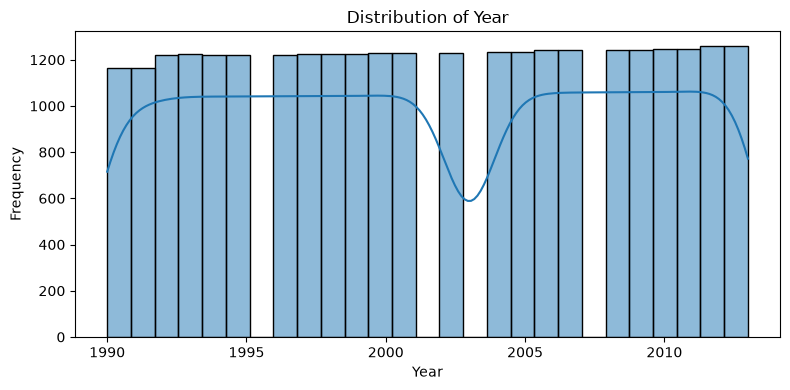

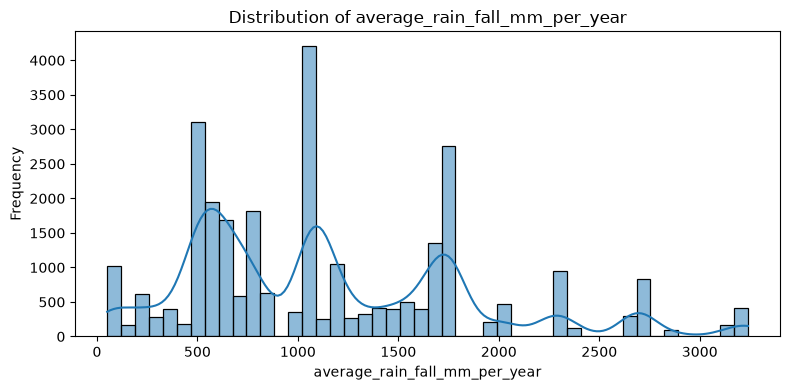

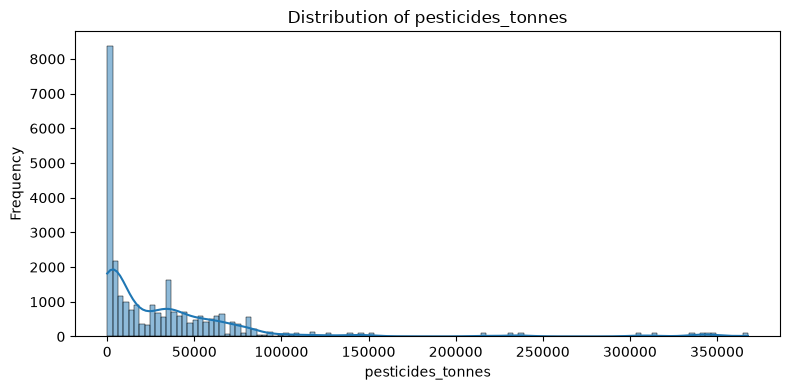

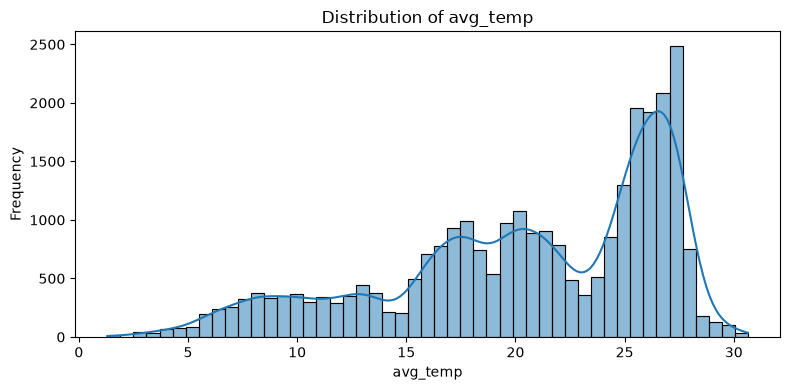

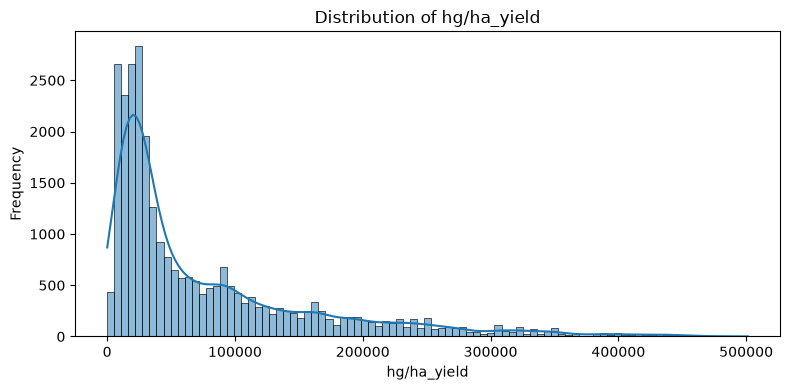

In [54]:
# ============================================================
# DISTRIBUTION PLOTS OF NUMERICAL FEATURES
# ============================================================

numerical_eda_features = [
    "Year",
    "average_rain_fall_mm_per_year",
    "pesticides_tonnes",
    "avg_temp",
    "hg/ha_yield"
]

for col in numerical_eda_features:
    plt.figure(figsize=(8, 4))
    
    sns.histplot(
        data=eda_df,
        x=col,
        kde=True
    )
    
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.show()

### Categorical Feature Distribution — Crop Types

The distribution of crop types is examined to identify how frequently each crop appears in the dataset and whether the observations are evenly distributed across crop categories.

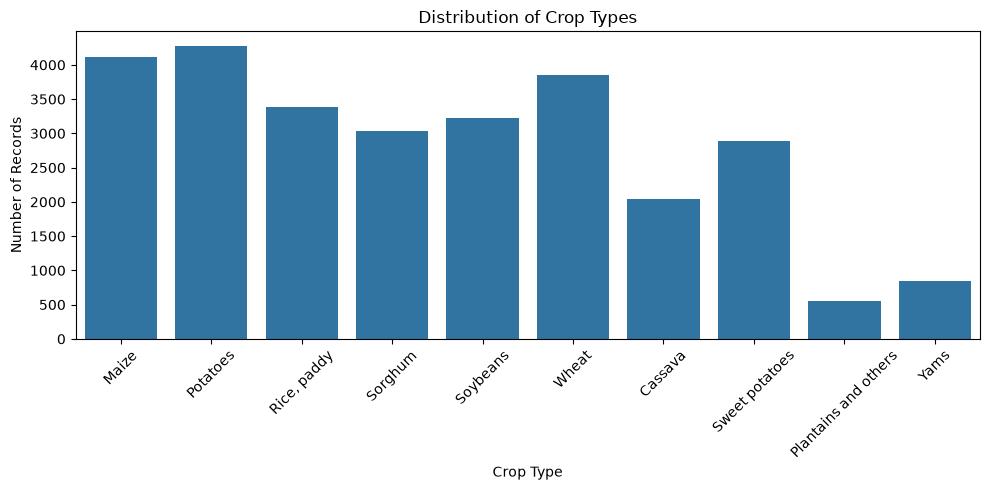

In [55]:
# ============================================================
# CATEGORICAL FEATURE DISTRIBUTION — CROP TYPES
# ============================================================

plt.figure(figsize=(10, 5))

sns.countplot(
    data=eda_df,
    x="Item"
)

plt.title("Distribution of Crop Types")
plt.xlabel("Crop Type")
plt.ylabel("Number of Records")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Categorical Feature Distribution — Areas

The ten areas with the highest number of observations are visualized to understand the geographic distribution of records in the dataset.

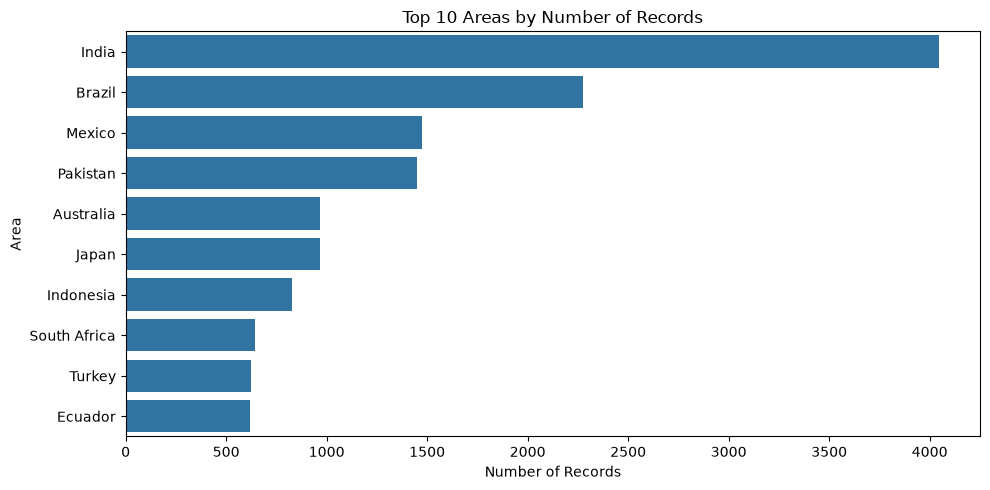

In [56]:
# ============================================================
# TOP 10 AREAS BY NUMBER OF RECORDS
# ============================================================

top_areas = eda_df["Area"].value_counts().head(10)

plt.figure(figsize=(10, 5))

sns.barplot(
    x=top_areas.values,
    y=top_areas.index
)

plt.title("Top 10 Areas by Number of Records")
plt.xlabel("Number of Records")
plt.ylabel("Area")
plt.tight_layout()
plt.show()

### Correlation Analysis

A correlation heatmap is used to examine the linear relationships among the numerical variables. The correlation coefficients range from -1 to +1, where values closer to +1 indicate a strong positive relationship, values closer to -1 indicate a strong negative relationship, and values near 0 indicate a weak linear relationship.

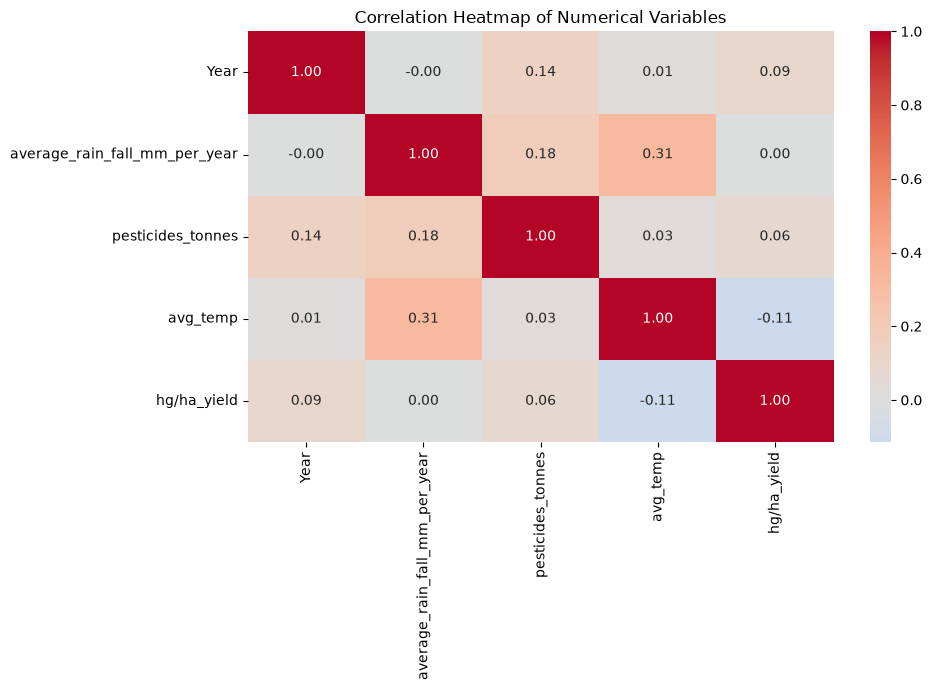

In [57]:
# ============================================================
# CORRELATION HEATMAP
# ============================================================

correlation_features = [
    "Year",
    "average_rain_fall_mm_per_year",
    "pesticides_tonnes",
    "avg_temp",
    "hg/ha_yield"
]

correlation_matrix = eda_df[correlation_features].corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Heatmap of Numerical Variables")
plt.tight_layout()
plt.show()

### Target Variable Distribution — Crop Yield

The distribution of the target variable, `hg/ha_yield`, is examined to understand the spread and frequency of crop-yield values. This helps identify the overall shape of the target distribution and the presence of potentially extreme observations.

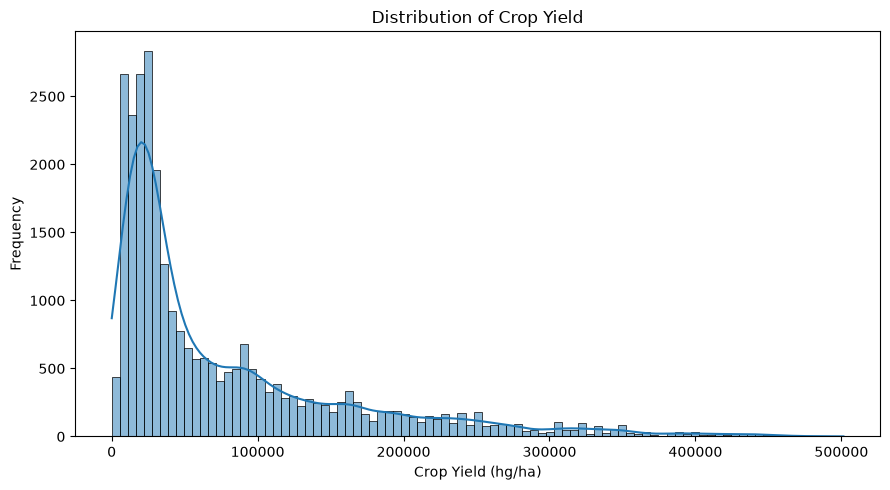

In [58]:
# ============================================================
# TARGET DISTRIBUTION — CROP YIELD
# ============================================================

plt.figure(figsize=(9, 5))

sns.histplot(
    data=eda_df,
    x="hg/ha_yield",
    kde=True
)

plt.title("Distribution of Crop Yield")
plt.xlabel("Crop Yield (hg/ha)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

### Feature-Target Relationships

Scatter plots are used to examine the relationships between important numerical predictors and crop yield. These visualizations help identify possible trends, patterns, and nonlinear relationships between the predictors and the target variable.

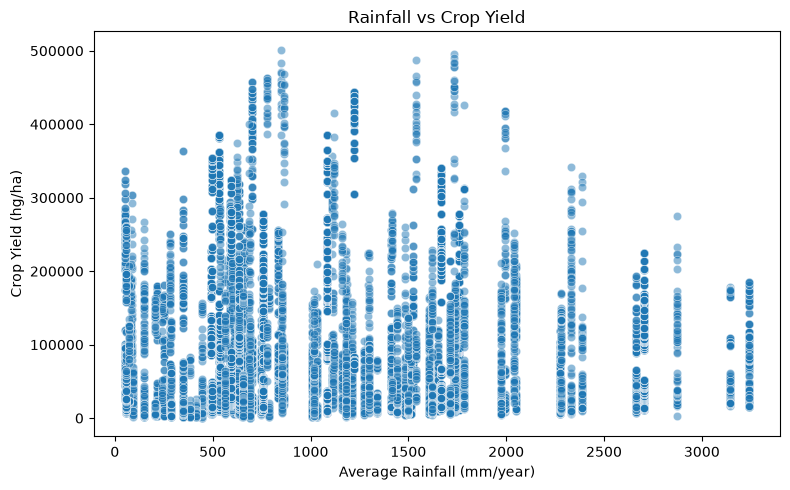

In [59]:
# ============================================================
# SCATTER PLOT 1 — RAINFALL VS YIELD
# ============================================================

plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=eda_df,
    x="average_rain_fall_mm_per_year",
    y="hg/ha_yield",
    alpha=0.5
)

plt.title("Rainfall vs Crop Yield")
plt.xlabel("Average Rainfall (mm/year)")
plt.ylabel("Crop Yield (hg/ha)")
plt.tight_layout()
plt.show()

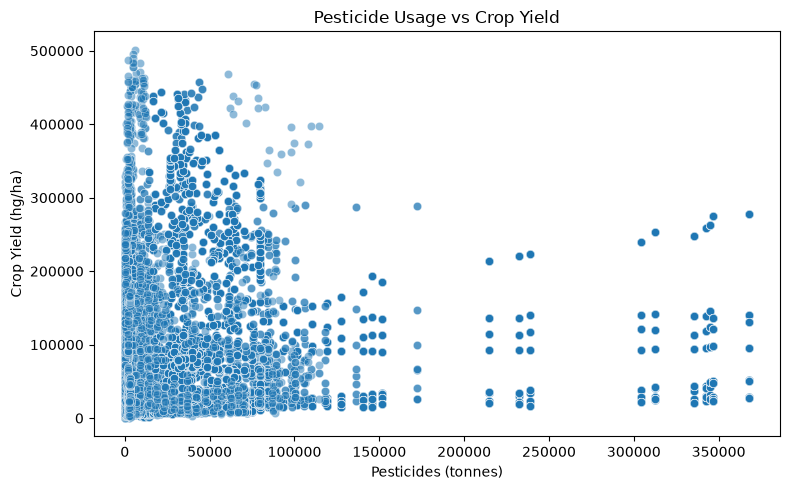

In [60]:
# ============================================================
# SCATTER PLOT 2 — PESTICIDES VS YIELD
# ============================================================

plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=eda_df,
    x="pesticides_tonnes",
    y="hg/ha_yield",
    alpha=0.5
)

plt.title("Pesticide Usage vs Crop Yield")
plt.xlabel("Pesticides (tonnes)")
plt.ylabel("Crop Yield (hg/ha)")
plt.tight_layout()
plt.show()

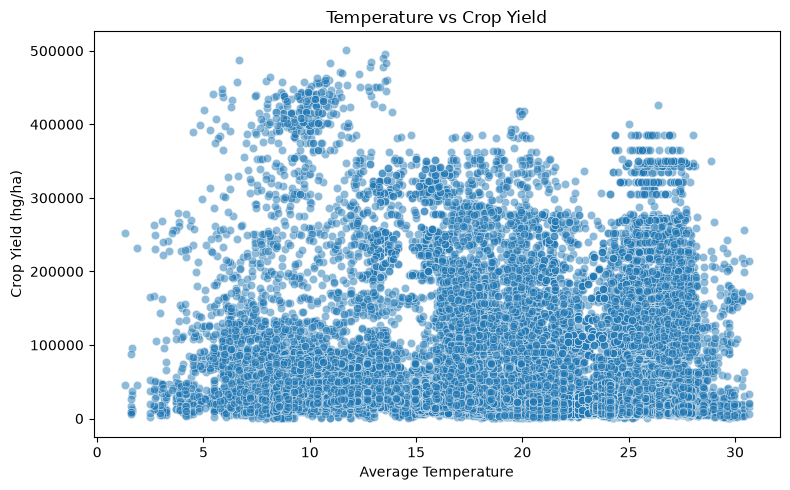

In [61]:
# ============================================================
# SCATTER PLOT 3 — TEMPERATURE VS YIELD
# ============================================================

plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=eda_df,
    x="avg_temp",
    y="hg/ha_yield",
    alpha=0.5
)

plt.title("Temperature vs Crop Yield")
plt.xlabel("Average Temperature")
plt.ylabel("Crop Yield (hg/ha)")
plt.tight_layout()
plt.show()

## A.3 EDA Insights and Observations

### Numerical Feature Distributions

- **Year:** The observations span multiple years, allowing the dataset to capture crop production patterns across different time periods.
- **Average Rainfall:** The rainfall values show variation across the observations, indicating different environmental conditions among the recorded areas.
- **Pesticides:** Pesticide usage varies substantially across the observations, reflecting differences in agricultural practices and production conditions.
- **Average Temperature:** The temperature distribution covers a range of climatic conditions across the different observations.
- **Crop Yield:** The target variable shows substantial variation in yield values, indicating that crop productivity differs considerably across crops, locations, and conditions.

### Categorical Feature Distributions

- **Crop Types:** The crop distribution shows that the number of observations is not identical across all crop categories.
- **Areas:** Among the top 10 areas displayed, **India has the highest number of records**, followed by Brazil, Mexico, and Pakistan. This indicates that the geographic observations are not uniformly distributed.

### Correlation Heatmap

- The numerical variables generally show weak linear correlations with crop yield. Temperature has the strongest direct correlation with yield among the displayed predictors, with a correlation of approximately **-0.11**.
- Rainfall has an approximately **zero linear correlation** with yield, while pesticides have a weak positive correlation of approximately **0.06**.
- Rainfall and temperature have the strongest relationship among the predictor variables, with a correlation of approximately **0.31**.

### Target Distribution

- The crop-yield distribution shows substantial variation in the target values, with observations concentrated at lower yield levels and a smaller number of observations having much higher yields.

### Feature-Target Relationships

- **Rainfall vs Crop Yield:** The scatter plot shows considerable variation in crop yield across rainfall levels, with no strong simple linear trend.
- **Pesticide Usage vs Crop Yield:** Crop yield varies considerably across pesticide usage levels, suggesting that pesticide usage alone does not explain yield variation.
- **Temperature vs Crop Yield:** The scatter plot shows a complex relationship between temperature and crop yield. Yield varies substantially at similar temperature values, suggesting that other factors and nonlinear relationships may also influence crop productivity.

## B. Preprocessing and Feature Engineering

The original dataset is prepared for regression modeling after exploratory analysis. Data cleaning, feature engineering, train-test splitting, and preprocessing are performed in a controlled sequence to prevent information leakage from the test set.

In [62]:
# ============================================================
# FRESH DATASET FOR FINAL MODELING
# ============================================================

model_df = pd.read_csv("../data/crop_yield/yield_df.csv")

# Remove unnecessary index column
if "Unnamed: 0" in model_df.columns:
    model_df = model_df.drop(columns=["Unnamed: 0"])

print("Original modeling dataset shape:", model_df.shape)
display(model_df.head())

Original modeling dataset shape: (28242, 7)


,Area,Item,Year,hg/ha_yield,average_rain_fall_mm_per_year,pesticides_tonnes,avg_temp
0,Albania,Maize,1990,36613,1485.0,121.0,16.37
1,Albania,Potatoes,1990,66667,1485.0,121.0,16.37
2,Albania,"Rice, paddy",1990,23333,1485.0,121.0,16.37
3,Albania,Sorghum,1990,12500,1485.0,121.0,16.37
4,Albania,Soybeans,1990,7000,1485.0,121.0,16.37


### B.1 Data Cleaning

Missing values and duplicate records are checked before model development. Missing numerical values, if present, are treated using median imputation. Duplicate records, if present, are removed. Conditional treatment is used so that the dataset is not artificially modified when no such issues exist.

In [64]:
# ============================================================
# MISSING VALUES AND DUPLICATES
# ============================================================

# Check missing values
print("Missing Values Before Treatment:")
print(model_df.isnull().sum())

# Treat missing numerical values if present
numeric_columns = model_df.select_dtypes(include="number").columns

for col in numeric_columns:
    if model_df[col].isnull().sum() > 0:
        model_df[col] = model_df[col].fillna(
            model_df[col].median()
        )

# Check duplicates
duplicate_count = model_df.duplicated().sum()

print("\nDuplicate Rows Before Treatment:", duplicate_count)

# Remove duplicates if present
if duplicate_count > 0:
    model_df = model_df.drop_duplicates()

# Verify
print("\nTotal Missing Values After Treatment:",
      model_df.isnull().sum().sum())

print("Duplicate Rows After Treatment:",
      model_df.duplicated().sum())

print("Dataset Shape After Cleaning:", model_df.shape)

Missing Values Before Treatment:
Area                             0
Item                             0
Year                             0
hg/ha_yield                      0
average_rain_fall_mm_per_year    0
pesticides_tonnes                0
avg_temp                         0
dtype: int64

Duplicate Rows Before Treatment: 2310

Total Missing Values After Treatment: 0
Duplicate Rows After Treatment: 0
Dataset Shape After Cleaning: (25932, 7)


### B.3 Feature Engineering

A rainfall-pesticide interaction feature is created by multiplying average annual rainfall by pesticide usage. This feature represents the combined effect of environmental water availability and agricultural input intensity and may help the regression models capture interactions between these variables.

In [65]:
# ============================================================
# FEATURE ENGINEERING
# ============================================================

model_df["rainfall_pesticide_interaction"] = (
    model_df["average_rain_fall_mm_per_year"]
    * model_df["pesticides_tonnes"]
)

print("Engineered feature created successfully.")

display(
    model_df[
        [
            "average_rain_fall_mm_per_year",
            "pesticides_tonnes",
            "rainfall_pesticide_interaction"
        ]
    ].head()
)

Engineered feature created successfully.


,average_rain_fall_mm_per_year,pesticides_tonnes,rainfall_pesticide_interaction
0,1485.0,121.0,179685.0
1,1485.0,121.0,179685.0
2,1485.0,121.0,179685.0
3,1485.0,121.0,179685.0
4,1485.0,121.0,179685.0


### B.2 Feature and Target Definition

The target variable is `hg/ha_yield`, representing crop yield. All remaining relevant variables are used as predictors. The target is separated from the feature matrix before splitting the dataset into training and testing sets.

In [66]:
# ============================================================
# DEFINE FEATURES AND TARGET
# ============================================================

target_column = "hg/ha_yield"

X = model_df.drop(columns=[target_column])
y = model_df[target_column]

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

print("\nFeatures:")
print(X.columns.tolist())

Feature shape: (25932, 7)
Target shape: (25932,)

Features:
['Area', 'Item', 'Year', 'average_rain_fall_mm_per_year', 'pesticides_tonnes', 'avg_temp', 'rainfall_pesticide_interaction']


### Stratified Train-Test Split

An 80:20 train-test split is used for model development and final evaluation. Since crop yield is a continuous target, quantile-based target bins are created only for stratification so that the training and testing sets maintain a similar distribution of target values. The original continuous target values are retained for regression.

In [67]:
# ============================================================
# STRATIFIED 80:20 TRAIN-TEST SPLIT
# ============================================================

from sklearn.model_selection import train_test_split

# Create bins only for stratification
y_bins = pd.qcut(
    y,
    q=10,
    labels=False,
    duplicates="drop"
)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y_bins
)

print("Training feature shape:", X_train.shape)
print("Testing feature shape:", X_test.shape)

print("\nTraining target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)

Training feature shape: (20745, 7)
Testing feature shape: (5187, 7)

Training target shape: (20745,)
Testing target shape: (5187,)


### Outlier Detection

Outliers in the numerical variables are identified using the Interquartile Range (IQR) method. The detected observations will be examined before deciding whether treatment is necessary, since extreme values may represent genuine agricultural conditions.

In [117]:
# ============================================================
# OUTLIER DETECTION USING IQR
# ============================================================

# Numerical columns for outlier analysis
numeric_columns = yield_combined_df.select_dtypes(include="number").columns

outlier_summary = []

for col in numeric_columns:
    Q1 = yield_combined_df[col].quantile(0.25)
    Q3 = yield_combined_df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outlier_count = (
        (yield_combined_df[col] < lower_bound) |
        (yield_combined_df[col] > upper_bound)
    ).sum()

    outlier_summary.append({
        "Feature": col,
        "Q1": Q1,
        "Q3": Q3,
        "IQR": IQR,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Outlier Count": outlier_count
    })

outlier_summary_df = pd.DataFrame(outlier_summary)

display(outlier_summary_df)

,Feature,Q1,Q3,IQR,Lower Bound,Upper Bound,Outlier Count
0,Year,1995.00,2008.00,13.00,1975.50,2.027500e+03,0
1,hg/ha_yield,19996.00,104168.00,84172.00,-106262.00,2.304260e+05,1918
2,average_rain_fall_mm_per_year,593.00,1668.00,1075.00,-1019.50,3.280500e+03,0
3,pesticides_tonnes,1597.00,45620.00,44023.00,-64437.50,1.116545e+05,0
4,avg_temp,16.58,26.06,9.48,2.36,4.028000e+01,0
5,rainfall_pesticide_interaction,1524152.88,46008612.48,44484459.60,-65202536.52,1.127353e+08,2524


### Outlier Visualization

Boxplots are used to visually inspect the numerical variables for extreme observations. The IQR analysis identified potential outliers in temperature and pesticide usage. These values will be treated using IQR-based capping for predictor variables while genuine extreme target values are retained.

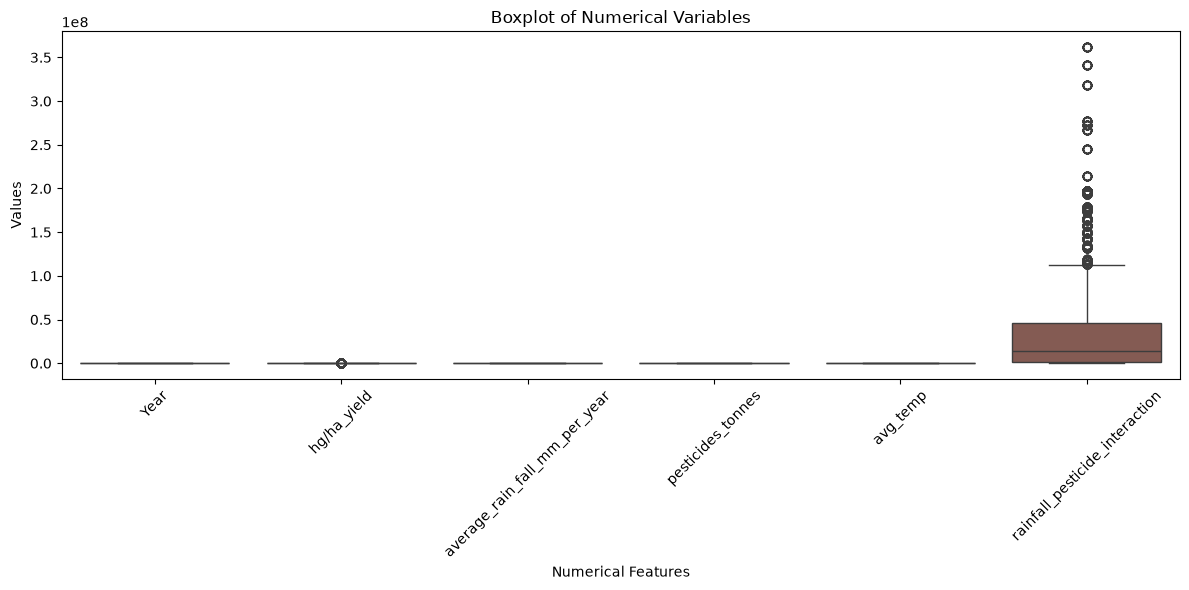

In [118]:
# ============================================================
# OUTLIER VISUALIZATION USING BOXPLOTS
# ============================================================

numeric_features = [
    "Year",
    "hg/ha_yield",
    "average_rain_fall_mm_per_year",
    "pesticides_tonnes",
    "avg_temp",
    "rainfall_pesticide_interaction"
]

plt.figure(figsize=(12, 6))

sns.boxplot(data=yield_combined_df[numeric_features])

plt.title("Boxplot of Numerical Variables")
plt.xlabel("Numerical Features")
plt.ylabel("Values")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Train-Only Outlier Treatment

Outlier boundaries are calculated using the training data only to prevent information from the test set influencing preprocessing. IQR-based capping is applied to the predictor variables `average_rain_fall_mm_per_year`, `pesticides_tonnes`, and `avg_temp`. The target variable is not modified because extreme crop-yield values may represent genuine observations.

In [68]:
# ============================================================
# OUTLIER TREATMENT USING TRAINING DATA ONLY
# ============================================================

outlier_columns = [
    "average_rain_fall_mm_per_year",
    "pesticides_tonnes",
    "avg_temp"
]

# Store boundaries calculated ONLY from training data
outlier_bounds = {}

for col in outlier_columns:

    Q1 = X_train[col].quantile(0.25)
    Q3 = X_train[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outlier_bounds[col] = {
        "lower": lower_bound,
        "upper": upper_bound
    }

    # Apply the TRAIN-derived boundaries to both datasets
    X_train[col] = X_train[col].clip(
        lower_bound,
        upper_bound
    )

    X_test[col] = X_test[col].clip(
        lower_bound,
        upper_bound
    )

print("Train-derived outlier treatment completed.")

display(pd.DataFrame(outlier_bounds).T)

Train-derived outlier treatment completed.


,lower,upper
average_rain_fall_mm_per_year,-1019.50,3280.50
pesticides_tonnes,-64437.50,111654.50
avg_temp,2.37,40.29


In [69]:
# ============================================================
# VERIFY TRAIN-ONLY OUTLIER TREATMENT
# ============================================================

verification = []

for col in outlier_columns:

    lower_bound = outlier_bounds[col]["lower"]
    upper_bound = outlier_bounds[col]["upper"]

    train_outliers = (
        (X_train[col] < lower_bound) |
        (X_train[col] > upper_bound)
    ).sum()

    test_outliers = (
        (X_test[col] < lower_bound) |
        (X_test[col] > upper_bound)
    ).sum()

    verification.append({
        "Feature": col,
        "Train Outliers Remaining": train_outliers,
        "Test Values Outside Train Bounds": test_outliers
    })

display(pd.DataFrame(verification))

,Feature,Train Outliers Remaining,Test Values Outside Train Bounds
0,average_rain_fall_mm_per_year,0,0
1,pesticides_tonnes,0,0
2,avg_temp,0,0


### Encoding and Feature Scaling

The categorical variables `Area` and `Item` are converted using One-Hot Encoding. Numerical variables are standardized using StandardScaler. The encoder and scaler are fitted exclusively on the training data and then applied to both training and testing data to prevent data leakage.

In [70]:
# ============================================================
# ENCODING AND SCALING
# ============================================================

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

categorical_features = [
    "Area",
    "Item"
]

numerical_features = [
    "Year",
    "average_rain_fall_mm_per_year",
    "pesticides_tonnes",
    "avg_temp",
    "rainfall_pesticide_interaction"
]

preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ),
            categorical_features
        ),
        (
            "numerical",
            StandardScaler(),
            numerical_features
        )
    ]
)

# FIT ONLY on training data
X_train_processed = preprocessor.fit_transform(X_train)

# Transform test data using the fitted transformer
X_test_processed = preprocessor.transform(X_test)

print("Original training shape:", X_train.shape)
print("Original testing shape:", X_test.shape)

print("\nProcessed training shape:", X_train_processed.shape)
print("Processed testing shape:", X_test_processed.shape)

Original training shape: (20745, 7)
Original testing shape: (5187, 7)

Processed training shape: (20745, 116)
Processed testing shape: (5187, 116)


In [71]:
# ============================================================
# PROCESSED FEATURE NAMES
# ============================================================

feature_names = preprocessor.get_feature_names_out()

print("Total processed features:", len(feature_names))

print("\nFirst 20 processed features:")
print(feature_names[:20])

Total processed features: 116

First 20 processed features:
['categorical__Area_Albania' 'categorical__Area_Algeria'
 'categorical__Area_Angola' 'categorical__Area_Argentina'
 'categorical__Area_Armenia' 'categorical__Area_Australia'
 'categorical__Area_Austria' 'categorical__Area_Azerbaijan'
 'categorical__Area_Bahamas' 'categorical__Area_Bahrain'
 'categorical__Area_Bangladesh' 'categorical__Area_Belarus'
 'categorical__Area_Belgium' 'categorical__Area_Botswana'
 'categorical__Area_Brazil' 'categorical__Area_Bulgaria'
 'categorical__Area_Burkina Faso' 'categorical__Area_Burundi'
 'categorical__Area_Cameroon' 'categorical__Area_Canada']


## C. Regression Modeling

Ten regression algorithms specified in the project guidelines are implemented and evaluated using the same training and testing split. The models are compared using R², RMSE, and MAE.

In [31]:
# ============================================================
# REGRESSION MODEL IMPORTS
# ============================================================

from sklearn.linear_model import (
    LinearRegression,
    Ridge,
    Lasso,
    ElasticNet
)

from sklearn.metrics import (
    r2_score,
    mean_squared_error,
    mean_absolute_error
)

import numpy as np
import pandas as pd

In [84]:
# ============================================================
# ADDITIONAL REGRESSION MODEL IMPORTS
# ============================================================

from sklearn.preprocessing import PolynomialFeatures
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor

print("All regression model imports completed successfully.")

All regression model imports completed successfully.


In [1]:
# ============================================================
# MODEL EVALUATION FUNCTION
# ============================================================

def evaluate_regression_model(model_name, model, X_train, X_test, y_train, y_test):
    
    # Train the model
    model.fit(X_train, y_train)
    
    # Generate predictions
    predictions = model.predict(X_test)
    
    # Calculate evaluation metrics
    r2 = r2_score(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    mae = mean_absolute_error(y_test, predictions)
    
    return {
        "Model": model_name,
        "R2": r2,
        "RMSE": rmse,
        "MAE": mae
    }, model, predictions

### Regression Model Evaluation

All ten regression algorithms specified in the project guidelines are evaluated using the same 80:20 train-test split and the final leakage-safe preprocessing pipeline. The evaluation metrics are R², RMSE, and MAE. Higher R² and lower RMSE and MAE indicate better predictive performance.

In [85]:
# ============================================================
# INITIALIZE FINAL REGRESSION EVALUATION
# ============================================================

regression_results = []
trained_models = {}
predictions_dict = {}

print("Regression evaluation initialized.")
print("Training samples:", X_train_processed.shape[0])
print("Testing samples:", X_test_processed.shape[0])
print("Processed features:", X_train_processed.shape[1])

Regression evaluation initialized.
Training samples: 20745
Testing samples: 5187
Processed features: 116


In [86]:
# ============================================================
# REGRESSION MODELS 1-4
# Linear Regression, Ridge, Lasso, ElasticNet
# ============================================================

models_1_4 = {
    "Linear Regression": LinearRegression(),
    "Ridge": Ridge(alpha=1.0),
    "Lasso": Lasso(alpha=0.01, max_iter=10000),
    "ElasticNet": ElasticNet(alpha=0.01, l1_ratio=0.5, max_iter=10000)
}

for model_name, model in models_1_4.items():

    result, trained_model, predictions = evaluate_regression_model(
        model_name,
        model,
        X_train_processed,
        X_test_processed,
        y_train,
        y_test
    )

    regression_results.append(result)
    trained_models[model_name] = trained_model
    predictions_dict[model_name] = predictions

print("Models 1-4 completed successfully.")

c:\Users\sande\OneDrive\Documents\SEM 5\AI ML\ML-Capstone-Project\.venv\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:840: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 8.829187e+12, tolerance: 1.496e+10
  model = cd_fast.enet_coordinate_descent(


Models 1-4 completed successfully.


In [87]:
# Display results for the first four models

results_1_4 = pd.DataFrame(regression_results)

display(
    results_1_4.sort_values(
        by="R2",
        ascending=False
    ).reset_index(drop=True)
)

,Model,R2,RMSE,MAE
0,Linear Regression,0.749664,41802.950010,29122.805328
1,Lasso,0.749664,41803.022705,29122.641277
2,Ridge,0.749455,41820.427880,29095.019914
3,ElasticNet,0.724306,43869.118951,28438.619722


In [88]:
# ============================================================
# MODEL 5: POLYNOMIAL REGRESSION
# Compare Degree 2 and Degree 3
# ============================================================

from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression

# Identify the processed numerical features
numeric_processed_indices = [
    i for i, name in enumerate(feature_names)
    if not name.startswith("categorical__")
]

X_train_numeric = X_train_processed[:, numeric_processed_indices]
X_test_numeric = X_test_processed[:, numeric_processed_indices]

polynomial_results = []

for degree in [2, 3]:

    poly = PolynomialFeatures(
        degree=degree,
        include_bias=False
    )

    X_train_poly = poly.fit_transform(X_train_numeric)
    X_test_poly = poly.transform(X_test_numeric)

    poly_model = LinearRegression()

    poly_model.fit(X_train_poly, y_train)

    poly_predictions = poly_model.predict(X_test_poly)

    r2 = r2_score(y_test, poly_predictions)
    rmse = np.sqrt(mean_squared_error(y_test, poly_predictions))
    mae = mean_absolute_error(y_test, poly_predictions)

    polynomial_results.append({
        "Degree": degree,
        "R2": r2,
        "RMSE": rmse,
        "MAE": mae
    })

polynomial_results_df = pd.DataFrame(polynomial_results)

display(
    polynomial_results_df.sort_values(
        by="R2",
        ascending=False
    ).reset_index(drop=True)
)

,Degree,R2,RMSE,MAE
0,3,0.062111,80913.572755,62497.675849
1,2,0.038236,81936.972786,62963.701916


### Polynomial Regression – Degree Comparison

Polynomial Regression was evaluated using polynomial degrees 2 and 3. Degree 3 achieved the better R² score and was therefore selected as the final Polynomial Regression model. Although its performance is lower than the linear models, the comparison demonstrates how increasing polynomial complexity affects predictive performance on this dataset.

In [89]:
# ============================================================
# STORE BEST POLYNOMIAL REGRESSION MODEL
# ============================================================

best_poly_row = polynomial_results_df.sort_values(
    by="R2",
    ascending=False
).iloc[0]

best_poly_degree = int(best_poly_row["Degree"])

regression_results.append({
    "Model": f"Polynomial Regression (Degree {best_poly_degree})",
    "R2": best_poly_row["R2"],
    "RMSE": best_poly_row["RMSE"],
    "MAE": best_poly_row["MAE"]
})

trained_models[f"Polynomial Regression (Degree {best_poly_degree})"] = poly_model
predictions_dict[f"Polynomial Regression (Degree {best_poly_degree})"] = poly_predictions

print(f"Polynomial Regression Degree {best_poly_degree} selected and stored.")

Polynomial Regression Degree 3 selected and stored.


## 6. Decision Tree Regressor

Decision Tree Regression is used to model nonlinear relationships between the input features and crop yield. The `max_depth` parameter controls the complexity of the tree. Different depth values are compared to identify a suitable model while reducing the risk of overfitting.

In [90]:
# ============================================================
# MODEL 6: DECISION TREE REGRESSOR
# Compare different max_depth values
# ============================================================

tree_depths = [5, 10, 15, 20, None]

tree_results = []

for depth in tree_depths:

    tree_model = DecisionTreeRegressor(
        max_depth=depth,
        random_state=42
    )

    tree_model.fit(X_train_processed, y_train)

    tree_predictions = tree_model.predict(X_test_processed)

    r2 = r2_score(y_test, tree_predictions)
    rmse = np.sqrt(mean_squared_error(y_test, tree_predictions))
    mae = mean_absolute_error(y_test, tree_predictions)

    tree_results.append({
        "max_depth": depth,
        "R2": r2,
        "RMSE": rmse,
        "MAE": mae
    })

tree_results_df = pd.DataFrame(tree_results)

display(
    tree_results_df.sort_values(
        by="R2",
        ascending=False
    ).reset_index(drop=True)
)

,max_depth,R2,RMSE,MAE
0,NaN,0.974193,13421.935318,3983.823212
1,20.0,0.973459,13611.466188,4708.890014
2,15.0,0.963212,16025.133650,7313.198412
3,10.0,0.921341,23432.491814,13616.683909
4,5.0,0.772016,39893.133015,25776.941727


### Decision Tree Results and Model Selection

Decision Tree Regression was evaluated with different values of `max_depth`. The model with no maximum depth achieved the highest R² score of approximately 0.9742 and was therefore selected as the best Decision Tree configuration. The results also show that restricting the tree depth reduces predictive performance on this dataset.

In [91]:
# ============================================================
# STORE BEST DECISION TREE MODEL
# ============================================================

best_tree_row = tree_results_df.sort_values(
    by="R2",
    ascending=False
).iloc[0]

best_tree_depth = best_tree_row["max_depth"]

best_tree_model = DecisionTreeRegressor(
    max_depth=None if pd.isna(best_tree_depth) else int(best_tree_depth),
    random_state=42
)

best_tree_model.fit(X_train_processed, y_train)

best_tree_predictions = best_tree_model.predict(X_test_processed)

regression_results.append({
    "Model": "Decision Tree (max_depth=None)" if pd.isna(best_tree_depth)
             else f"Decision Tree (max_depth={int(best_tree_depth)})",
    "R2": r2_score(y_test, best_tree_predictions),
    "RMSE": np.sqrt(mean_squared_error(y_test, best_tree_predictions)),
    "MAE": mean_absolute_error(y_test, best_tree_predictions)
})

trained_models["Decision Tree"] = best_tree_model
predictions_dict["Decision Tree"] = best_tree_predictions

print("Best Decision Tree model stored successfully.")
print("Selected max_depth:", best_tree_depth)

Best Decision Tree model stored successfully.
Selected max_depth: nan


## 7. Random Forest Regressor

Random Forest Regression combines multiple decision trees to improve predictive performance and reduce the dependence on a single tree. The `n_estimators` parameter controls the number of trees in the forest. Different values are compared to identify a suitable configuration.

In [92]:
# ============================================================
# MODEL 7: RANDOM FOREST REGRESSOR
# Compare different n_estimators values
# ============================================================

forest_estimators = [50, 100, 200]

forest_results = []

for n in forest_estimators:

    forest_model = RandomForestRegressor(
        n_estimators=n,
        random_state=42,
        n_jobs=-1
    )

    forest_model.fit(X_train_processed, y_train)

    forest_predictions = forest_model.predict(X_test_processed)

    r2 = r2_score(y_test, forest_predictions)
    rmse = np.sqrt(mean_squared_error(y_test, forest_predictions))
    mae = mean_absolute_error(y_test, forest_predictions)

    forest_results.append({
        "n_estimators": n,
        "R2": r2,
        "RMSE": rmse,
        "MAE": mae
    })

forest_results_df = pd.DataFrame(forest_results)

display(
    forest_results_df.sort_values(
        by="R2",
        ascending=False
    ).reset_index(drop=True)
)

,n_estimators,R2,RMSE,MAE
0,200,0.987258,9431.174501,3661.670756
1,100,0.987047,9509.005354,3683.475309
2,50,0.986785,9604.573447,3724.308452


### Random Forest Results and Model Selection

Random Forest Regression was evaluated using 50, 100, and 200 trees. The configuration with 200 estimators achieved the highest R² score of approximately 0.9873 and the lowest RMSE and MAE among the tested configurations. Therefore, the 200-tree Random Forest is selected as the best Random Forest configuration.

In [93]:
# ============================================================
# STORE BEST RANDOM FOREST MODEL
# ============================================================

best_forest_row = forest_results_df.sort_values(
    by="R2",
    ascending=False
).iloc[0]

best_n_estimators = int(best_forest_row["n_estimators"])

best_forest_model = RandomForestRegressor(
    n_estimators=best_n_estimators,
    random_state=42,
    n_jobs=-1
)

best_forest_model.fit(X_train_processed, y_train)

best_forest_predictions = best_forest_model.predict(X_test_processed)

best_forest_result = {
    "Model": f"Random Forest (n_estimators={best_n_estimators})",
    "R2": r2_score(y_test, best_forest_predictions),
    "RMSE": np.sqrt(mean_squared_error(y_test, best_forest_predictions)),
    "MAE": mean_absolute_error(y_test, best_forest_predictions)
}

regression_results.append(best_forest_result)

trained_models["Random Forest"] = best_forest_model
predictions_dict["Random Forest"] = best_forest_predictions

print("Best Random Forest model stored successfully.")
print("Selected n_estimators:", best_n_estimators)


Best Random Forest model stored successfully.
Selected n_estimators: 200


## 8. Gradient Boosting Regressor

Gradient Boosting Regression builds an ensemble of weak learners sequentially, where each new tree attempts to reduce the errors made by the previous trees. The `learning_rate` controls the contribution of each tree. Different learning-rate values are compared to identify a suitable configuration.

In [94]:
# ============================================================
# MODEL 8: GRADIENT BOOSTING REGRESSOR
# Compare different learning_rate values
# ============================================================

learning_rates = [0.05, 0.1, 0.2]

gb_results = []

for rate in learning_rates:

    gb_model = GradientBoostingRegressor(
        learning_rate=rate,
        n_estimators=100,
        random_state=42
    )

    gb_model.fit(X_train_processed, y_train)

    gb_predictions = gb_model.predict(X_test_processed)

    r2 = r2_score(y_test, gb_predictions)
    rmse = np.sqrt(mean_squared_error(y_test, gb_predictions))
    mae = mean_absolute_error(y_test, gb_predictions)

    gb_results.append({
        "learning_rate": rate,
        "R2": r2,
        "RMSE": rmse,
        "MAE": mae
    })

gb_results_df = pd.DataFrame(gb_results)

display(
    gb_results_df.sort_values(
        by="R2",
        ascending=False
    ).reset_index(drop=True)
)

,learning_rate,R2,RMSE,MAE
0,0.20,0.896896,26827.742966,17332.814625
1,0.10,0.860208,31238.232099,20285.683811
2,0.05,0.810553,36365.538724,23961.391481


### Gradient Boosting Results and Model Selection

Gradient Boosting Regression was evaluated using learning rates of 0.05, 0.10, and 0.20. The learning rate of 0.20 achieved the highest R² score of approximately 0.8969 and the lowest RMSE and MAE among the tested configurations. Therefore, this configuration is selected as the best Gradient Boosting model.

In [95]:
# ============================================================
# STORE BEST GRADIENT BOOSTING MODEL
# ============================================================

best_gb_row = gb_results_df.sort_values(
    by="R2",
    ascending=False
).iloc[0]

best_learning_rate = float(best_gb_row["learning_rate"])

best_gb_model = GradientBoostingRegressor(
    learning_rate=best_learning_rate,
    n_estimators=100,
    random_state=42
)

best_gb_model.fit(X_train_processed, y_train)

best_gb_predictions = best_gb_model.predict(X_test_processed)

best_gb_result = {
    "Model": f"Gradient Boosting (learning_rate={best_learning_rate})",
    "R2": r2_score(y_test, best_gb_predictions),
    "RMSE": np.sqrt(mean_squared_error(y_test, best_gb_predictions)),
    "MAE": mean_absolute_error(y_test, best_gb_predictions)
}

regression_results.append(best_gb_result)

trained_models["Gradient Boosting"] = best_gb_model
predictions_dict["Gradient Boosting"] = best_gb_predictions

print("Best Gradient Boosting model stored successfully.")
print("Selected learning_rate:", best_learning_rate)

Best Gradient Boosting model stored successfully.
Selected learning_rate: 0.2


## 9. Support Vector Regression (SVR)

Support Vector Regression is evaluated because it can model nonlinear relationships while controlling model complexity. Since SVR is sensitive to feature scale, the numerical features were standardized during preprocessing. Different values of `C` and kernel types are compared to identify a suitable configuration.

In [96]:
# ============================================================
# MODEL 9: SUPPORT VECTOR REGRESSION
# Compare C and kernel configurations
# ============================================================

svr_configurations = [
    {"C": 1, "kernel": "linear"},
    {"C": 10, "kernel": "linear"},
    {"C": 10, "kernel": "rbf"}
]

svr_results = []

for config in svr_configurations:

    print(
        f"Training SVR: C={config['C']}, "
        f"kernel={config['kernel']}"
    )

    svr_model = SVR(
        C=config["C"],
        kernel=config["kernel"]
    )

    svr_model.fit(X_train_processed, y_train)

    svr_predictions = svr_model.predict(X_test_processed)

    r2 = r2_score(y_test, svr_predictions)
    rmse = np.sqrt(mean_squared_error(y_test, svr_predictions))
    mae = mean_absolute_error(y_test, svr_predictions)

    svr_results.append({
        "C": config["C"],
        "kernel": config["kernel"],
        "R2": r2,
        "RMSE": rmse,
        "MAE": mae
    })

svr_results_df = pd.DataFrame(svr_results)

display(
    svr_results_df.sort_values(
        by="R2",
        ascending=False
    ).reset_index(drop=True)
)

Training SVR: C=1, kernel=linear
Training SVR: C=10, kernel=linear
Training SVR: C=10, kernel=rbf


,C,kernel,R2,RMSE,MAE
0,10,linear,0.138052,77568.640517,44864.662966
1,1,linear,-0.161495,90043.884728,55010.367297
2,10,rbf,-0.169357,90348.120194,55325.210744


### SVR Results and Model Selection

Support Vector Regression was evaluated using different values of `C` and kernel types. The configuration with `C = 10` and a linear kernel produced the best SVR performance, with an R² score of approximately 0.1381. However, SVR performed substantially worse than the tree-based regression models on this dataset. This indicates that SVR was not well suited to capturing the complex relationships present in the crop-yield data under the tested configurations.

In [97]:
# ============================================================
# STORE BEST SVR MODEL
# ============================================================

best_svr_row = svr_results_df.sort_values(
    by="R2",
    ascending=False
).iloc[0]

best_svr_C = float(best_svr_row["C"])
best_svr_kernel = best_svr_row["kernel"]

best_svr_model = SVR(
    C=best_svr_C,
    kernel=best_svr_kernel
)

best_svr_model.fit(X_train_processed, y_train)

best_svr_predictions = best_svr_model.predict(X_test_processed)

trained_models["SVR"] = best_svr_model
predictions_dict["SVR"] = best_svr_predictions

print("Best SVR model stored successfully.")
print("Selected C:", best_svr_C)
print("Selected kernel:", best_svr_kernel)

Best SVR model stored successfully.
Selected C: 10.0
Selected kernel: linear


## 10. K-Nearest Neighbors Regression

K-Nearest Neighbors (KNN) Regression predicts the target value based on nearby observations in feature space. Since KNN is distance-based, the standardized feature representation is used. Different values of `k` are evaluated to determine the most suitable neighborhood size.

In [98]:
# ============================================================
# MODEL 10: K-NEAREST NEIGHBORS REGRESSION
# Compare different values of k
# ============================================================

knn_k_values = [3, 5, 10, 15, 20]

knn_results = []

for k in knn_k_values:

    print(f"Training KNN: k={k}")

    knn_model = KNeighborsRegressor(
        n_neighbors=k
    )

    knn_model.fit(X_train_processed, y_train)

    knn_predictions = knn_model.predict(X_test_processed)

    r2 = r2_score(y_test, knn_predictions)
    rmse = np.sqrt(mean_squared_error(y_test, knn_predictions))
    mae = mean_absolute_error(y_test, knn_predictions)

    knn_results.append({
        "k": k,
        "R2": r2,
        "RMSE": rmse,
        "MAE": mae
    })

knn_results_df = pd.DataFrame(knn_results)

display(
    knn_results_df.sort_values(
        by="R2",
        ascending=False
    ).reset_index(drop=True)
)

Training KNN: k=3
Training KNN: k=5
Training KNN: k=10
Training KNN: k=15
Training KNN: k=20


,k,R2,RMSE,MAE
0,3,0.985123,10190.852983,4252.266371
1,5,0.981570,11342.602754,4793.279969
2,10,0.966330,15330.895443,6978.824523
3,15,0.936664,21026.742784,10472.085663
4,20,0.905876,25632.842682,13438.978735


## KNN Results and Model Selection

K-Nearest Neighbors was evaluated using different neighborhood sizes. The best performance was obtained with `k = 3`, achieving an R² score of approximately 0.9851. Increasing the value of `k` resulted in progressively lower performance, indicating that a smaller neighborhood was more suitable for this dataset.

In [99]:
# ============================================================
# STORE BEST KNN MODEL
# ============================================================

best_knn_row = knn_results_df.sort_values(
    by="R2",
    ascending=False
).iloc[0]

best_knn_k = int(best_knn_row["k"])

best_knn_model = KNeighborsRegressor(
    n_neighbors=best_knn_k
)

best_knn_model.fit(X_train_processed, y_train)

best_knn_predictions = best_knn_model.predict(X_test_processed)

trained_models["KNN"] = best_knn_model
predictions_dict["KNN"] = best_knn_predictions

print("Best KNN model stored successfully.")
print("Selected k:", best_knn_k)

Best KNN model stored successfully.
Selected k: 3


## Final Regression Model Comparison

All ten regression algorithms required by the project guidelines have now been evaluated using the same 80:20 train-test split and the same leakage-safe preprocessing pipeline. The models are compared using R², RMSE, and MAE. The final table is ranked by R², where a higher R² and lower RMSE and MAE indicate better predictive performance.

In [100]:
# ============================================================
# FINAL COMPARISON TABLE — ALL 10 REGRESSION MODELS
# ============================================================

final_regression_results = [
    {
        "Model": "Linear Regression",
        "R2": 0.749664,
        "RMSE": 41802.950010,
        "MAE": 29122.805328
    },
    {
        "Model": "Ridge",
        "R2": 0.749455,
        "RMSE": 41820.427880,
        "MAE": 29095.019914
    },
    {
        "Model": "Lasso",
        "R2": 0.749664,
        "RMSE": 41803.022705,
        "MAE": 29122.641277
    },
    {
        "Model": "ElasticNet",
        "R2": 0.724306,
        "RMSE": 43869.118951,
        "MAE": 28438.619722
    },
    {
        "Model": "Polynomial Regression",
        "R2": 0.062111,
        "RMSE": 80913.572755,
        "MAE": 62497.675849
    },
    {
        "Model": "Decision Tree",
        "R2": 0.974193,
        "RMSE": 13421.935318,
        "MAE": 3983.823212
    },
    {
        "Model": "Random Forest",
        "R2": 0.987258,
        "RMSE": 9431.174501,
        "MAE": 3661.670756
    },
    {
        "Model": "Gradient Boosting",
        "R2": 0.896896,
        "RMSE": 26827.742966,
        "MAE": 17332.814625
    },
    {
        "Model": "SVR",
        "R2": 0.138052,
        "RMSE": 77568.640517,
        "MAE": 44864.662966
    },
    {
        "Model": "KNN",
        "R2": 0.985123,
        "RMSE": 10190.852983,
        "MAE": 4252.266371
    }
]

final_regression_df = pd.DataFrame(final_regression_results)

final_regression_df = (
    final_regression_df
    .sort_values(by="R2", ascending=False)
    .reset_index(drop=True)
)

display(final_regression_df)

,Model,R2,RMSE,MAE
0,Random Forest,0.987258,9431.174501,3661.670756
1,KNN,0.985123,10190.852983,4252.266371
2,Decision Tree,0.974193,13421.935318,3983.823212
3,Gradient Boosting,0.896896,26827.742966,17332.814625
4,Lasso,0.749664,41803.022705,29122.641277
5,Linear Regression,0.749664,41802.950010,29122.805328
6,Ridge,0.749455,41820.427880,29095.019914
7,ElasticNet,0.724306,43869.118951,28438.619722
8,SVR,0.138052,77568.640517,44864.662966
9,Polynomial Regression,0.062111,80913.572755,62497.675849


## C3. Hyperparameter Tuning

The two best-performing regression models from the initial comparison, Random Forest Regressor and K-Nearest Neighbors Regressor, are selected for hyperparameter tuning. GridSearchCV is used to systematically evaluate different hyperparameter combinations using cross-validation. The tuned models are then evaluated on the same held-out test set to determine whether performance improves.

In [101]:
# ============================================================
# HYPERPARAMETER TUNING IMPORTS
# ============================================================

from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestRegressor
from sklearn.neighbors import KNeighborsRegressor

print("Hyperparameter tuning tools imported successfully.")

Hyperparameter tuning tools imported successfully.


### Random Forest Hyperparameter Tuning

Random Forest is tuned using different numbers of trees and maximum tree depths. The objective is to identify a configuration that improves the predictive performance while maintaining generalization.

In [102]:
# ============================================================
# RANDOM FOREST — GRIDSEARCHCV
# ============================================================

rf_base = RandomForestRegressor(
    random_state=42,
    n_jobs=-1
)

rf_param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [None, 15, 20]
}

rf_grid = GridSearchCV(
    estimator=rf_base,
    param_grid=rf_param_grid,
    cv=3,
    scoring="r2",
    n_jobs=-1
)

print("Starting Random Forest GridSearchCV...")

rf_grid.fit(X_train_processed, y_train)

print("Random Forest tuning completed.")
print("\nBest Parameters:")
print(rf_grid.best_params_)

print("\nBest Cross-Validation R2:")
print(rf_grid.best_score_)

Starting Random Forest GridSearchCV...
Random Forest tuning completed.

Best Parameters:
{'max_depth': None, 'n_estimators': 200}

Best Cross-Validation R2:
0.9809078344714881


In [103]:
# ============================================================
# EVALUATE TUNED RANDOM FOREST
# ============================================================

rf_tuned_model = rf_grid.best_estimator_

rf_tuned_predictions = rf_tuned_model.predict(X_test_processed)

rf_tuned_r2 = r2_score(y_test, rf_tuned_predictions)
rf_tuned_rmse = np.sqrt(
    mean_squared_error(y_test, rf_tuned_predictions)
)
rf_tuned_mae = mean_absolute_error(
    y_test,
    rf_tuned_predictions
)

print("Tuned Random Forest Test Performance")
print("-------------------------------------")
print("R2:", rf_tuned_r2)
print("RMSE:", rf_tuned_rmse)
print("MAE:", rf_tuned_mae)

print("\nOriginal Random Forest Test Performance")
print("----------------------------------------")
original_rf = final_regression_df[
    final_regression_df["Model"] == "Random Forest"
].iloc[0]

print("R2:", original_rf["R2"])
print("RMSE:", original_rf["RMSE"])
print("MAE:", original_rf["MAE"])

Tuned Random Forest Test Performance
-------------------------------------
R2: 0.9872579203767419
RMSE: 9431.17450118767
MAE: 3661.6707557354925

Original Random Forest Test Performance
----------------------------------------
R2: 0.987258
RMSE: 9431.174501
MAE: 3661.670756


### K-Nearest Neighbors Hyperparameter Tuning

KNN Regression is further tuned using neighborhood size, distance weighting, and the Minkowski distance parameter. Since KNN is highly sensitive to the definition of neighborhood distance and the contribution of nearby observations, these parameters may improve its predictive performance.

In [104]:
# ============================================================
# KNN — GRIDSEARCHCV
# ============================================================

knn_base = KNeighborsRegressor()

knn_param_grid = {
    "n_neighbors": [2, 3, 4, 5, 7, 10],
    "weights": ["uniform", "distance"],
    "p": [1, 2]
}

knn_grid = GridSearchCV(
    estimator=knn_base,
    param_grid=knn_param_grid,
    cv=3,
    scoring="r2",
    n_jobs=-1
)

print("Starting KNN GridSearchCV...")

knn_grid.fit(X_train_processed, y_train)

print("KNN tuning completed.")

print("\nBest Parameters:")
print(knn_grid.best_params_)

print("\nBest Cross-Validation R2:")
print(knn_grid.best_score_)


Starting KNN GridSearchCV...
KNN tuning completed.

Best Parameters:
{'n_neighbors': 3, 'p': 1, 'weights': 'distance'}

Best Cross-Validation R2:
0.9855144121851939


In [105]:
# ============================================================
# EVALUATE TUNED KNN ON TEST SET
# ============================================================

knn_tuned_model = knn_grid.best_estimator_

knn_tuned_predictions = knn_tuned_model.predict(X_test_processed)

knn_tuned_r2 = r2_score(
    y_test,
    knn_tuned_predictions
)

knn_tuned_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        knn_tuned_predictions
    )
)

knn_tuned_mae = mean_absolute_error(
    y_test,
    knn_tuned_predictions
)

print("Tuned KNN Test Performance")
print("---------------------------")
print("R2:", knn_tuned_r2)
print("RMSE:", knn_tuned_rmse)
print("MAE:", knn_tuned_mae)

print("\nOriginal KNN Test Performance")
print("-----------------------------")

original_knn = final_regression_df[
    final_regression_df["Model"] == "KNN"
].iloc[0]

print("R2:", original_knn["R2"])
print("RMSE:", original_knn["RMSE"])
print("MAE:", original_knn["MAE"])

Tuned KNN Test Performance
---------------------------
R2: 0.9887156373308016
RMSE: 8875.322461780932
MAE: 3524.2415133190852

Original KNN Test Performance
-----------------------------
R2: 0.985123
RMSE: 10190.852983
MAE: 4252.266371


In [106]:
# ============================================================
# HYPERPARAMETER TUNING COMPARISON
# ============================================================

tuning_comparison = pd.DataFrame([
    {
        "Model": "Random Forest - Original",
        "R2": original_rf["R2"],
        "RMSE": original_rf["RMSE"],
        "MAE": original_rf["MAE"]
    },
    {
        "Model": "Random Forest - Tuned",
        "R2": rf_tuned_r2,
        "RMSE": rf_tuned_rmse,
        "MAE": rf_tuned_mae
    },
    {
        "Model": "KNN - Original",
        "R2": original_knn["R2"],
        "RMSE": original_knn["RMSE"],
        "MAE": original_knn["MAE"]
    },
    {
        "Model": "KNN - Tuned",
        "R2": knn_tuned_r2,
        "RMSE": knn_tuned_rmse,
        "MAE": knn_tuned_mae
    }
])

display(tuning_comparison)

,Model,R2,RMSE,MAE
0,Random Forest - Original,0.987258,9431.174501,3661.670756
1,Random Forest - Tuned,0.987258,9431.174501,3661.670756
2,KNN - Original,0.985123,10190.852983,4252.266371
3,KNN - Tuned,0.988716,8875.322462,3524.241513


In [107]:
# ============================================================
# STORE TUNED KNN MODEL
# ============================================================

trained_models["KNN_Tuned"] = knn_tuned_model
predictions_dict["KNN_Tuned"] = knn_tuned_predictions

print("Tuned KNN model stored successfully.")

Tuned KNN model stored successfully.


## C4. Best Model Analysis

Random Forest Regressor achieved the highest predictive performance among the ten evaluated regression algorithms. The tuned Random Forest model is therefore selected for detailed analysis. Predicted-versus-actual and residual plots are used to assess prediction quality and error patterns, while feature importance is examined to identify the variables contributing most strongly to the model's predictions.

In [108]:
# ============================================================
# STORE FINAL RANDOM FOREST MODEL
# ============================================================

final_rf_model = rf_tuned_model
final_rf_predictions = rf_tuned_predictions

trained_models["Random Forest Final"] = final_rf_model
predictions_dict["Random Forest Final"] = final_rf_predictions

print("Final Random Forest model selected successfully.")

Final Random Forest model selected successfully.


### Predicted vs Actual Values

The predicted-versus-actual plot compares the values predicted by the final Random Forest model with the actual crop-yield values in the test set. Points closer to the diagonal reference line indicate more accurate predictions.

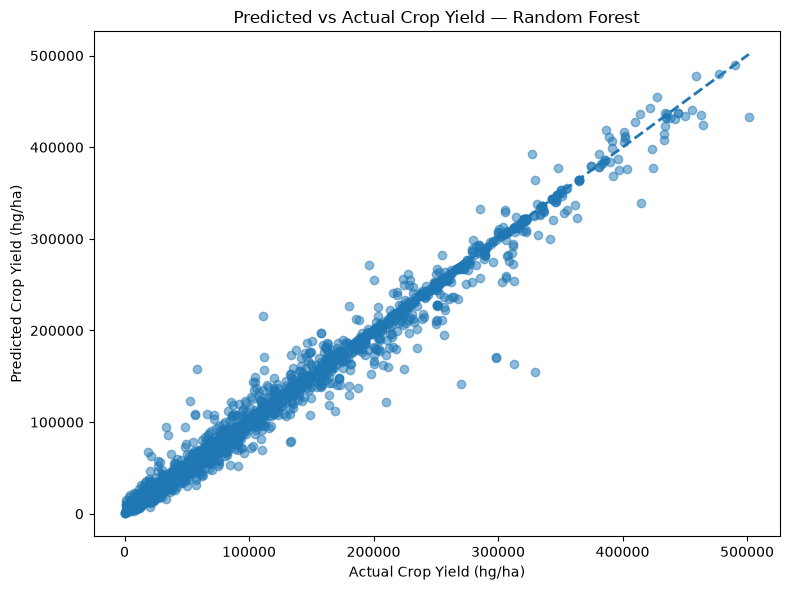

In [109]:
# ============================================================
# PREDICTED VS ACTUAL PLOT
# ============================================================

plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    final_rf_predictions,
    alpha=0.5
)

# Perfect prediction reference line
min_value = min(y_test.min(), final_rf_predictions.min())
max_value = max(y_test.max(), final_rf_predictions.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--",
    linewidth=2
)

plt.xlabel("Actual Crop Yield (hg/ha)")
plt.ylabel("Predicted Crop Yield (hg/ha)")
plt.title("Predicted vs Actual Crop Yield — Random Forest")
plt.tight_layout()
plt.show()

### Residual Analysis

Residuals are calculated as the difference between actual and predicted crop-yield values. The residual plot is used to identify systematic patterns or changes in error magnitude across predicted values. Ideally, residuals should be distributed around zero without a strong systematic pattern.

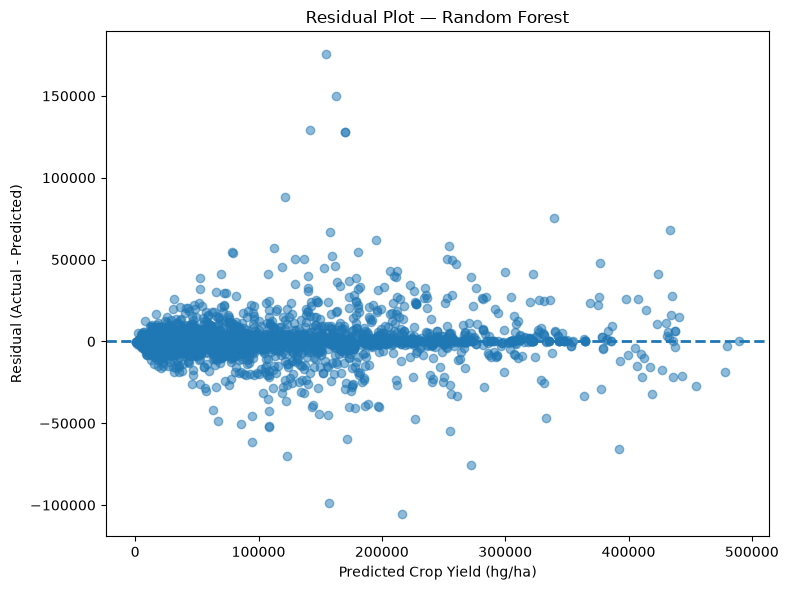

In [110]:
# ============================================================
# RESIDUAL PLOT
# ============================================================

residuals = y_test - final_rf_predictions

plt.figure(figsize=(8, 6))

plt.scatter(
    final_rf_predictions,
    residuals,
    alpha=0.5
)

plt.axhline(
    y=0,
    linestyle="--",
    linewidth=2
)

plt.xlabel("Predicted Crop Yield (hg/ha)")
plt.ylabel("Residual (Actual - Predicted)")
plt.title("Residual Plot — Random Forest")
plt.tight_layout()
plt.show()

### Random Forest Feature Importance

Random Forest provides feature importance scores that indicate the relative contribution of each processed feature to the model's predictions. The most important features are visualized to understand which variables have the greatest influence on crop-yield prediction.

In [111]:
# ============================================================
# RANDOM FOREST FEATURE IMPORTANCE
# ============================================================

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": final_rf_model.feature_importances_
})

feature_importance = (
    feature_importance
    .sort_values(
        by="Importance",
        ascending=False
    )
    .reset_index(drop=True)
)

display(feature_importance.head(15))

,Feature,Importance
0,categorical__Item_Potatoes,0.375083
1,categorical__Item_Cassava,0.092504
2,categorical__Item_Sweet potatoes,0.083986
3,numerical__pesticides_tonnes,0.065609
4,categorical__Area_India,0.055499
5,numerical__avg_temp,0.042007
6,numerical__average_rain_fall_mm_per_year,0.041472
7,numerical__Year,0.033125
8,categorical__Item_Yams,0.024834
9,categorical__Area_Japan,0.016634


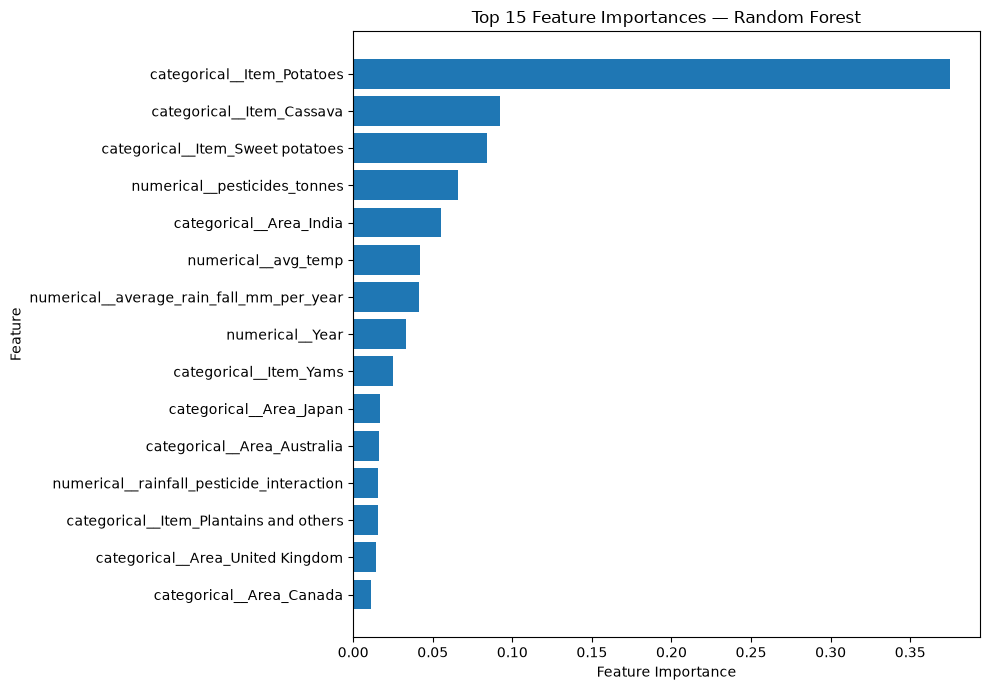

In [112]:
# ============================================================
# TOP 15 FEATURE IMPORTANCES
# ============================================================

top_features = feature_importance.head(15)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features["Feature"][::-1],
    top_features["Importance"][::-1]
)

plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Top 15 Feature Importances — Random Forest")
plt.tight_layout()
plt.show()

### Feature Importance — Key Observation

The Random Forest feature-importance analysis shows that crop type is highly influential in the prediction task. `Item_Potatoes` has the highest importance by a substantial margin, followed by `Item_Cassava` and `Item_Sweet potatoes`. `pesticides_tonnes`, `Area_India`, `avg_temp`, and `average_rain_fall_mm_per_year` also contribute to the model's predictions.

The importance values represent the contribution of features to the Random Forest's predictive decisions and should not be interpreted as causal relationships. The strong contribution of crop-type and geographic features suggests that crop yield varies considerably across different crops and regions.

## 5-Fold Cross-Validation of the Two Best Models

The two best-performing regression models, Random Forest and KNN, are further evaluated using 5-fold cross-validation. Cross-validation is performed on the training data so that the held-out test set remains completely untouched for final evaluation. The preprocessing transformer is included inside each cross-validation pipeline to prevent information leakage between folds.

In [114]:
# ============================================================
# 5-FOLD CROSS-VALIDATION IMPORTS
# ============================================================

from sklearn.model_selection import cross_val_score
from sklearn.pipeline import Pipeline

print("Cross-validation tools imported successfully.")

Cross-validation tools imported successfully.


In [115]:
# ============================================================
# 5-FOLD CROSS-VALIDATION
# RANDOM FOREST AND KNN
# ============================================================

# Random Forest pipeline
rf_cv_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        **rf_grid.best_params_,
        random_state=42,
        n_jobs=-1
    ))
])

# Tuned KNN pipeline
knn_cv_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", KNeighborsRegressor(
        **knn_grid.best_params_
    ))
])

print("Running 5-fold CV for Random Forest...")

rf_cv_scores = cross_val_score(
    rf_cv_pipeline,
    X_train,
    y_train,
    cv=5,
    scoring="r2",
    n_jobs=-1
)

print("Random Forest CV completed.")

print("\nRunning 5-fold CV for KNN...")

knn_cv_scores = cross_val_score(
    knn_cv_pipeline,
    X_train,
    y_train,
    cv=5,
    scoring="r2",
    n_jobs=-1
)

print("KNN CV completed.")

Running 5-fold CV for Random Forest...
Random Forest CV completed.

Running 5-fold CV for KNN...
KNN CV completed.


In [116]:
# ============================================================
# 5-FOLD CROSS-VALIDATION SUMMARY
# ============================================================

cv_results = pd.DataFrame({
    "Model": [
        "Random Forest",
        "KNN"
    ],
    "Fold 1 R2": [
        rf_cv_scores[0],
        knn_cv_scores[0]
    ],
    "Fold 2 R2": [
        rf_cv_scores[1],
        knn_cv_scores[1]
    ],
    "Fold 3 R2": [
        rf_cv_scores[2],
        knn_cv_scores[2]
    ],
    "Fold 4 R2": [
        rf_cv_scores[3],
        knn_cv_scores[3]
    ],
    "Fold 5 R2": [
        rf_cv_scores[4],
        knn_cv_scores[4]
    ],
    "Mean CV R2": [
        rf_cv_scores.mean(),
        knn_cv_scores.mean()
    ],
    "Std CV R2": [
        rf_cv_scores.std(),
        knn_cv_scores.std()
    ]
})

display(cv_results)

,Model,Fold 1 R2,Fold 2 R2,Fold 3 R2,Fold 4 R2,Fold 5 R2,Mean CV R2,Std CV R2
0,Random Forest,0.983870,0.979942,0.988279,0.983642,0.983133,0.983773,0.002662
1,KNN,0.986937,0.981283,0.989492,0.986790,0.985951,0.986091,0.002680


### Cross-Validation Observation

Five-fold cross-validation provides an estimate of how consistently the two strongest models perform across different subsets of the training data. The mean R² represents the average cross-validation performance, while the standard deviation indicates the variation between folds. These results are considered alongside the held-out test-set performance when selecting the final regression model.